In [3]:
import pandas as pd
import seaborn as sb
import numpy as np
from sklearn.metrics import adjusted_rand_score

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

# Show all rows
pd.set_option('display.max_rows', None)

# Show all columns
pd.set_option('display.max_columns', None)

# (Optional) Show full text in cells
pd.set_option('display.max_colwidth', None)

ss = StandardScaler()
pca = PCA()

df = pd.read_excel('Dry_Bean_Dataset.xlsx')

# Exclude sample_id and Class from clustering
sample_ids = df['sample_id']
x = df.drop(columns=['sample_id', 'Class'])

# Standardize the original features
x_scaled = ss.fit_transform(x)

Data Preparation

=========Agg clustering========

With normalization

In [4]:
# Agglomerative Clustering with normalization

agg = AgglomerativeClustering(n_clusters=7, linkage='ward')

agg_results = agg.fit_predict(x_scaled)

# Cluster sizes
print(pd.Series(agg_results).value_counts().sort_index())

# Silhouette score
print("Silhouette Score:", silhouette_score(x_scaled, agg_results))

0    3036
1    1677
2    3063
3    1918
4    3278
5     522
6     117
Name: count, dtype: int64
Silhouette Score: 0.28385468114878754


Metrics, Data visualization and Label traits

<Axes: xlabel='PC1', ylabel='PC2'>

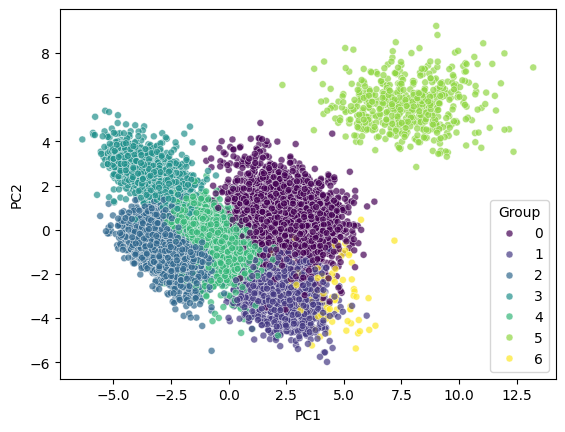

In [5]:
# Reduce standardized features to 2 dimensions for visualization
pca_2d = PCA(n_components=2)
x_agg_2d = pca_2d.fit_transform(x_scaled)

df_agg_viz = pd.DataFrame({
    'PC1': x_agg_2d[:, 0],
    'PC2': x_agg_2d[:, 1],
    'Group': agg_results
})

sb.scatterplot(
    data=df_agg_viz,
    x='PC1',
    y='PC2',
    hue='Group',
    palette='viridis',
    s=25,
    alpha=0.7
)

In [6]:
# Measurements of the categories

df_agg_analysis = x.copy()
df_agg_analysis['Cluster'] = agg_results

df_agg_analysis.groupby('Cluster').mean()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
Cluster,,,,,,,,,,,,,,,,
0,72467.828393,1049.501498,391.717272,236.579048,1.661207,0.791211,73644.041831,302.967438,0.754626,0.983951,0.823956,0.775435,0.005459,0.001225,0.602659,0.992561
1,53625.025641,920.543785,374.536597,182.773634,2.051213,0.871709,54330.046512,260.723748,0.703509,0.986961,0.792972,0.696841,0.007043,0.001027,0.485961,0.993758
2,31264.815540,656.007549,243.270282,163.559891,1.489499,0.736275,31633.807705,199.071639,0.751361,0.988292,0.909525,0.819400,0.007847,0.002189,0.672105,0.997002
3,39522.677789,723.071626,248.851055,201.999702,1.232427,0.576195,39902.978102,223.948467,0.773457,0.990456,0.947582,0.900999,0.006332,0.002583,0.812366,0.998412
4,43688.936852,785.741044,294.205834,189.408422,1.554493,0.761406,44215.996644,235.424322,0.750583,0.987998,0.887031,0.801561,0.006775,0.001733,0.643174,0.995647
5,173485.059387,1585.619079,593.152075,374.352547,1.585550,0.770518,175813.116858,468.941426,0.776559,0.986902,0.864421,0.792622,0.003442,0.000844,0.629195,0.991841
6,57765.333333,954.443385,372.941371,201.958160,1.852826,0.837671,59841.239316,270.224722,0.710265,0.965315,0.791812,0.725780,0.006548,0.001125,0.527648,0.971077


With normalization and PCA

In [7]:
# PCA using standardized original features
pca_agg = PCA()
x_agg_pca_full = pca_agg.fit_transform(x_scaled)

# Retain the first 8 components
x_agg_pca = x_agg_pca_full[:, :8]

print("Components:", x_agg_pca.shape[1])
print(
    "Variance retained:",
    f"{pca_agg.explained_variance_ratio_[:8].sum():.2%}"
)

Components: 8
Variance retained: 99.93%


In [8]:
agg_pca = AgglomerativeClustering(
    n_clusters=7,
    linkage='ward'
)

agg_pca_results = agg_pca.fit_predict(x_agg_pca)

print("Silhouette Score:", silhouette_score(x_agg_pca, agg_pca_results))

print("\nCluster sizes:")
print(pd.Series(agg_pca_results).value_counts().sort_index())

Silhouette Score: 0.2812475799491543

Cluster sizes:
0    2877
1    1744
2    2431
3    1880
4    4040
5     522
6     117
Name: count, dtype: int64


Data visualization and cluster traits

<Axes: xlabel='PC1', ylabel='PC2'>

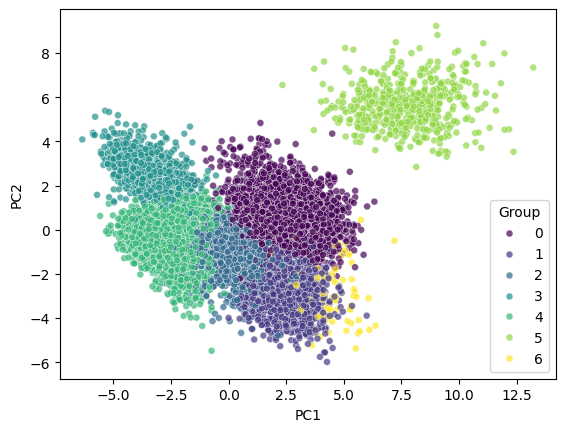

In [9]:
pca_agg_2d = PCA(n_components=2)
x_agg_2d_pca = pca_agg_2d.fit_transform(x_scaled)

df_agg_pca_viz = pd.DataFrame({
    'PC1': x_agg_2d_pca[:, 0],
    'PC2': x_agg_2d_pca[:, 1],
    'Group': agg_pca_results
})

sb.scatterplot(
    data=df_agg_pca_viz,
    x='PC1',
    y='PC2',
    hue='Group',
    palette='viridis',
    s=25,
    alpha=0.7
)

In [10]:
# analyzing the traits of the clusters with PCA

df_agg_pca_analysis = x.copy()
df_agg_pca_analysis['Cluster'] = agg_pca_results

df_agg_pca_analysis.groupby('Cluster').mean()


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
Cluster,,,,,,,,,,,,,,,,
0,73311.316302,1055.353718,392.723314,238.741293,1.648393,0.788125,74494.165450,304.819021,0.754811,0.984070,0.824945,0.778362,0.005398,0.001232,0.607091,0.992956
1,54314.581995,926.791662,376.609998,184.308074,2.046596,0.870990,55049.822248,262.447673,0.703660,0.986613,0.792544,0.697455,0.006989,0.001022,0.486834,0.993144
2,44450.074044,798.294612,301.348750,188.186957,1.603155,0.777829,45025.043603,237.392278,0.739243,0.987070,0.873443,0.788946,0.006833,0.001639,0.623076,0.994763
3,39454.502660,722.416211,248.380636,202.025940,1.229934,0.574206,39834.955851,223.755892,0.774030,0.990439,0.947684,0.901865,0.006332,0.002592,0.813899,0.998417
4,33873.409158,680.823301,251.976291,170.416414,1.481146,0.733506,34255.173020,206.836290,0.758687,0.988733,0.911342,0.821569,0.007560,0.002129,0.675561,0.997124
5,173485.059387,1585.619079,593.152075,374.352547,1.585550,0.770518,175813.116858,468.941426,0.776559,0.986902,0.864421,0.792622,0.003442,0.000844,0.629195,0.991841
6,57765.333333,954.443385,372.941371,201.958160,1.852826,0.837671,59841.239316,270.224722,0.710265,0.965315,0.791812,0.725780,0.006548,0.001125,0.527648,0.971077


--------comparing--------

In [11]:
# Compare clustering configurations

configurations = {
    "Agglomerative - Standardized": (x_scaled, agg_results),
    "Agglomerative - PCA": (x_agg_pca, agg_pca_results)
}

comparison = []

for name, (features, cluster_labels) in configurations.items():
    sizes = pd.Series(cluster_labels).value_counts().sort_index()

    comparison.append({
        "Configuration": name,
        "Silhouette Score": round(
            silhouette_score(features, cluster_labels), 4
        ),
        "Number of Clusters": len(sizes),
        "Cluster Sizes": sizes.to_dict()
    })

comparison_df = pd.DataFrame(comparison)
display(comparison_df)

,Configuration,Silhouette Score,Number of Clusters,Cluster Sizes
0,Agglomerative - Standardized,0.2839,7,"{0: 3036, 1: 1677, 2: 3063, 3: 1918, 4: 3278, 5: 522, 6: 117}"
1,Agglomerative - PCA,0.2812,7,"{0: 2877, 1: 1744, 2: 2431, 3: 1880, 4: 4040, 5: 522, 6: 117}"


In [12]:
display(
    "Agglomerative agreement:",
    round(adjusted_rand_score(agg_results, agg_pca_results), 4)
)

'Agglomerative agreement:'

0.7248